In [2]:
%pip install statsmodels

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
   -- ------------------------------------- 0.8/11.3 MB 2.1 MB/s eta 0:00:06
   ---- ----------------------------------- 1.3/11.3 MB 2.2 MB/s eta 0:00:05
   ----- ---------------------------------- 1.6/11.3 MB 2.0 MB/s eta 0:00:05
   ------- -------------------------------- 2.1/11.3 MB 1.9 MB/s eta 0:00:05
   -------- ------------------------------- 2.4/11.3 MB 1.9 MB/s eta 0:00:05
   ---------- ----------------------------- 2.9/11.3 MB 2.0 MB/s eta 0:00:05
   ------------ --------------------------- 3.4/11.3 MB 2.1 MB/s eta 0:00:04
   ------------- -------------------------- 3.9/11.3 MB 2.1 MB/s eta 0:00:04
   --------------- ------------------------ 4.5/11.3 MB 2.2 MB/s eta 0:00:04
   ----------------- ---------------------- 5.0/11.3 MB 2.1 MB/s eta 0:00:03
   -----------------

In [2]:
%pip install tensorflow

  Using cached tensorflow-2.21.0-cp312-cp312-win_amd64.whl.metadata (4.5 kB)
  Using cached absl_py-2.5.1-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached grpcio-1.84.0-cp312-cp312-win_amd64.whl.metadata (3.9 kB)
  Using cached keras-3.15.1-py3-none-any.whl.metadata (6.4 kB)
  Using cached h5py-3.14.0-cp312-cp312-win_amd64.whl.metadata (2.7 kB)
  Using cached ml_dtypes-0.6.0-cp312-cp312-win_amd64.whl.metadata (8.8 kB)
  Using cach

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.metrics import mean_squared_error, mean_absolute_error
from math import sqrt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, SimpleRNN, LSTM, GRU, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import json
import random

In [2]:
# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)

In [3]:
# Hyperparameters (tweak these)
CSV_PATH = "/mnt/data/monthly_milk_production.csv"
WINDOW_SIZE = 12               # input window size (12 months)
TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15
BATCH_SIZE = 16
EPOCHS = 150
PATIENCE = 10
UNITS = 64
DROPOUT = 0.0
FORECAST_HORIZON = 12         # forecast next 12 months
OUT_DIR = "/mnt/data/milk_forecasts_output"
os.makedirs(OUT_DIR, exist_ok=True)

In [4]:
df = pd.read_csv("C:/Users/adish/Downloads/monthly_milk_production.csv")
print("Columns:", df.columns.tolist())
print("\nFirst 5 rows:")
display(df.head())      

Columns: ['Date', 'Production']

First 5 rows:


,Date,Production
0,1962-01,589
1,1962-02,561
2,1962-03,640
3,1962-04,656
4,1962-05,727


In [5]:
# Heuristic: find date-like column and numeric column
date_col = None
for c in df.columns:
    parsed = pd.to_datetime(df[c], errors='coerce')
    if parsed.notna().sum() > len(df) * 0.5:
        date_col = c
        break
if date_col is None:
    date_col = df.columns[0]

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
if not numeric_cols:
    if len(df.columns) > 1:
        # try converting second column to numeric
        df[df.columns[1]] = pd.to_numeric(df[df.columns[1]], errors='coerce')
        numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
if not numeric_cols:
    raise ValueError("No numeric column found — can't proceed.")

value_col = max(numeric_cols, key=lambda c: df[c].std(skipna=True))
print(f"Inferred date column: {date_col} | value column: {value_col}")

# ---------------------------
# Step 2: Build time series, reindex to monthly, clean missing
# ---------------------------
df[date_col] = pd.to_datetime(df[date_col], errors='coerce')
ts = df[[date_col, value_col]].dropna().rename(columns={date_col: 'ds', value_col: 'y'})
ts = ts.sort_values('ds').reset_index(drop=True)
ts = ts.set_index('ds')

# reindex to monthly start frequency (MS) between min and max
monthly_index = pd.date_range(start=ts.index.min(), end=ts.index.max(), freq='MS')
ts = ts.reindex(monthly_index)
ts.index.name = 'ds'

# Fill small gaps with linear interpolation
missing_before = ts['y'].isna().sum()
ts['y'] = ts['y'].interpolate(method='linear')
missing_after = ts['y'].isna().sum()
print(f"Missing months before: {missing_before} | after interpolation: {missing_after}")




Inferred date column: Date | value column: Production
Missing months before: 0 | after interpolation: 0



Time series summary:


,y
count,168.000000
mean,754.708333
std,102.204524
min,553.000000
25%,677.750000
50%,761.000000
75%,824.500000
max,969.000000


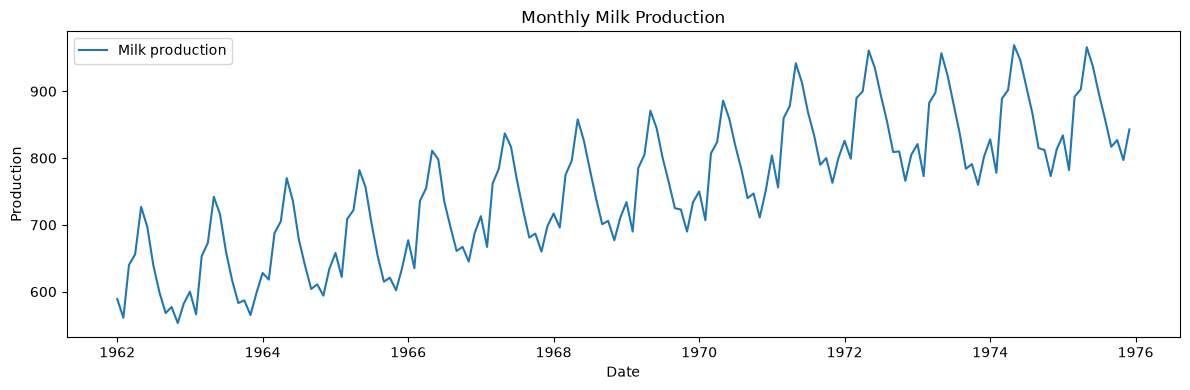

In [6]:
# Quick summary
print("\nTime series summary:")
display(ts.describe())

# ---------------------------
# Step 3: Exploratory Data Analysis (EDA)
# ---------------------------
plt.figure(figsize=(12,4))
plt.plot(ts.index, ts['y'], label='Milk production')
plt.title("Monthly Milk Production")
plt.xlabel("Date")
plt.ylabel("Production")
plt.legend()
plt.tight_layout()
plt.show()

C:\Users\adish\AppData\Local\Temp\ipykernel_1560\2933138019.py:3: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  decomposition = seasonal_decompose(ts['y'], model='additive', period=12, extrapolate_trend='freq')


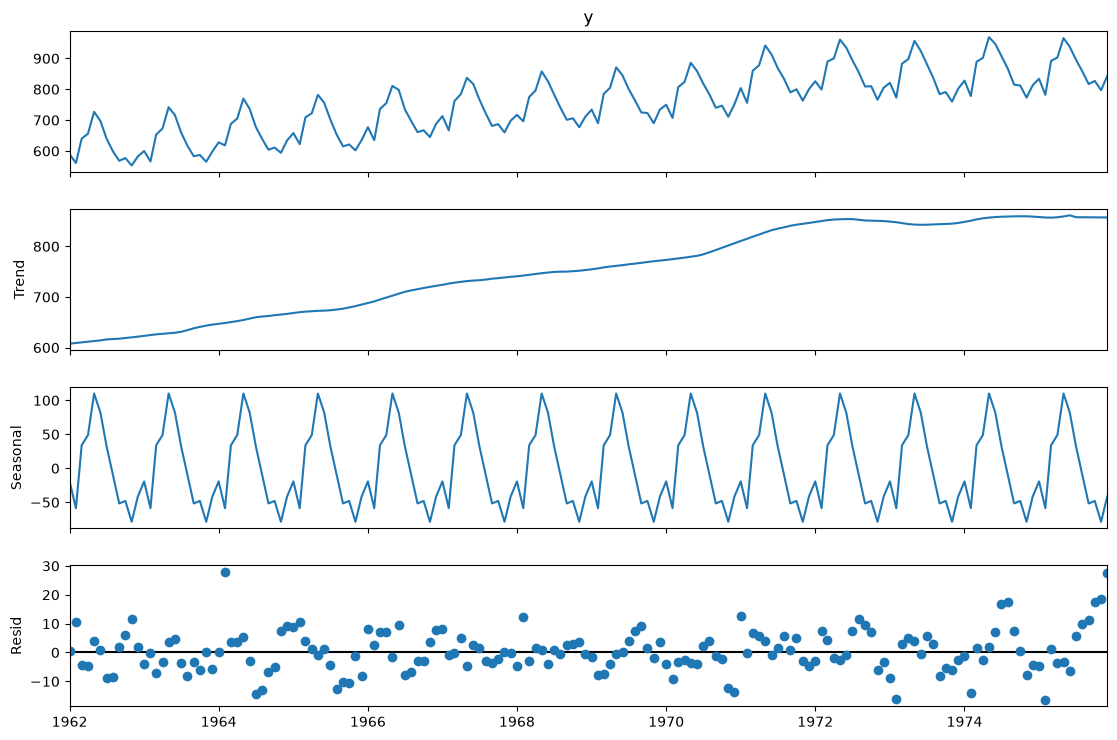

In [7]:
# Seasonal decomposition (period=12 for monthly)
try:
    decomposition = seasonal_decompose(ts['y'], model='additive', period=12, extrapolate_trend='freq')
    fig = decomposition.plot()
    fig.set_size_inches(12,8)
    plt.show()
except Exception as w:
    print("Seasonal decomposition failed:", e)

In [8]:
# Check for outliers (simple z-score)
ts['z'] = (ts['y'] - ts['y'].mean()) / ts['y'].std()
outliers = ts[np.abs(ts['z']) > 3]
print("Detected outliers (|z|>3):", len(outliers))
if len(outliers) > 0:
    display(outliers)

Detected outliers (|z|>3): 0


In [9]:
# ---------------------------
# Step 4: Normalize / Scale (Min-Max)
# ---------------------------
y = ts['y'].values.astype('float32')
y_min, y_max = y.min(), y.max()
if y_max == y_min:
    raise ValueError("Series is constant — cannot scale.")
y_scaled = (y - y_min) / (y_max - y_min)
     

# ---------------------------
# Step 5: Create input-output sequences (windowing)
# ---------------------------
def create_sequences(series, window_size=12):
    X, Y = [], []
    for i in range(len(series) - window_size):
        X.append(series[i:i+window_size])
        Y.append(series[i+window_size])
    return np.array(X), np.array(Y)

X, Y = create_sequences(y_scaled, WINDOW_SIZE)
print("Created sequences -> X shape:", X.shape, "Y shape:", Y.shape)

Created sequences -> X shape: (156, 12) Y shape: (156,)


In [10]:
# ---------------------------
# Step 6: Split into train / val / test (temporal split)
# ---------------------------
n = len(X)
train_end = int(n * TRAIN_RATIO)
val_end = train_end + int(n * VAL_RATIO)

X_train, Y_train = X[:train_end], Y[:train_end]
X_val, Y_val = X[train_end:val_end], Y[train_end:val_end]
X_test, Y_test = X[val_end:], Y[val_end:]

# reshape for RNN models: (samples, timesteps, features)
X_train_r = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_val_r = X_val.reshape((X_val.shape[0], X_val.shape[1], 1))
X_test_r = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

print("Split sizes -> train:", X_train_r.shape, "val:", X_val_r.shape, "test:", X_test_r.shape)

# Helper to inverse scale
def inv_scale(arr_scaled):
    return arr_scaled * (y_max - y_min) + y_min


Split sizes -> train: (109, 12, 1) val: (23, 12, 1) test: (24, 12, 1)


In [11]:
# Step 7: Model builder (RNN, LSTM, GRU)
# ---------------------------
def build_model(cell_type='RNN', units=UNITS, window=WINDOW_SIZE, dropout=DROPOUT):
    model = Sequential()
    if cell_type == 'RNN':
        model.add(SimpleRNN(units, input_shape=(window,1)))
    elif cell_type == 'LSTM':
        model.add(LSTM(units, input_shape=(window,1)))
    elif cell_type == 'GRU':
        model.add(GRU(units, input_shape=(window,1)))
    else:
        raise ValueError("cell_type must be one of 'RNN','LSTM','GRU'")
    if dropout and dropout > 0:
        model.add(Dropout(dropout))
    model.add(Dense(1, activation='linear'))
    model.compile(optimizer='adam', loss='mse')
    return model

In [12]:
# Step 8: Train and evaluate function
# ---------------------------
def train_and_eval(cell_type):
    print(f"\n--- Training {cell_type} ---")
    model = build_model(cell_type=cell_type)
    es = EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True, verbose=1)
    history = model.fit(
        X_train_r, Y_train,
        validation_data=(X_val_r, Y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[es],
        verbose=1
    )
    # Predictions (scaled)
    pred_test_scaled = model.predict(X_test_r).flatten()
    y_test_true = inv_scale(Y_test)
    pred_test_true = inv_scale(pred_test_scaled)

    rmse = sqrt(mean_squared_error(y_test_true, pred_test_true))
    mae = mean_absolute_error(y_test_true, pred_test_true)
    mape = np.mean(np.abs((y_test_true - pred_test_true) / (y_test_true + 1e-8))) * 100

    # Build dataframe of test preds aligned with dates
    test_start_idx = WINDOW_SIZE + val_end  # index into original ts array where test Y corresponds
    test_dates = ts.index[test_start_idx : test_start_idx + len(Y_test)]
    df_test_pred = pd.DataFrame({
        'ds': test_dates,
        'y_true': y_test_true,
        'y_pred': pred_test_true
    }).set_index('ds')

    print(f"{cell_type} -> RMSE: {rmse:.4f}, MAE: {mae:.4f}, MAPE: {mape:.2f}%")
    return {'model': model, 'history': history, 'metrics': {'rmse': rmse, 'mae': mae, 'mape': mape}, 'df_test_pred': df_test_pred}


In [13]:
# Step 9: Train all three models
# ---------------------------
results = {}
for c in ['RNN','LSTM','GRU']:
    results[c] = train_and_eval(c)



--- Training RNN ---
Epoch 1/150


C:\Users\adish\anaconda3\envs\ds_clustering\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 61ms/step - loss: 0.0576 - val_loss: 0.0488
Epoch 2/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0190 - val_loss: 0.0079
Epoch 3/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0120 - val_loss: 0.0124
Epoch 4/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0079 - val_loss: 0.0098
Epoch 5/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0061 - val_loss: 0.0058
Epoch 6/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0046 - val_loss: 0.0094
Epoch 7/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0040 - val_loss: 0.0054
Epoch 8/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0034 - val_loss: 0.0071
Epoch 9/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0030 - val_loss: 0.0047
Epoch 10/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0027 - val_loss: 0.0055
Epoch 11/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0025 - val_loss: 0.0045
Epoch 12/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0023 - val_loss: 0.0048
E

C:\Users\adish\anaconda3\envs\ds_clustering\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - loss: 0.1319 - val_loss: 0.1503
Epoch 2/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0392 - val_loss: 0.0274
Epoch 3/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0337 - val_loss: 0.0276
Epoch 4/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0252 - val_loss: 0.0391
Epoch 5/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0262 - val_loss: 0.0409
Epoch 6/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0250 - val_loss: 0.0290
Epoch 7/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0241 - val_loss: 0.0260
Epoch 8/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0237 - val_loss: 0.0280
Epoch 9/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0232 - val_loss: 0.0294
Epoch 10/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0230 - val_loss: 0.0270
Epoch 11/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0226 - val_loss: 0.0256
Epoch 12/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0222 - val_loss: 0.0256
E

C:\Users\adish\anaconda3\envs\ds_clustering\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - loss: 0.1038 - val_loss: 0.0895
Epoch 2/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0299 - val_loss: 0.0265
Epoch 3/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0328 - val_loss: 0.0242
Epoch 4/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0237 - val_loss: 0.0390
Epoch 5/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0236 - val_loss: 0.0433
Epoch 6/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0227 - val_loss: 0.0325
Epoch 7/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0213 - val_loss: 0.0258
Epoch 8/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0209 - val_loss: 0.0258
Epoch 9/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0201 - val_loss: 0.0281
Epoch 10/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0196 - val_loss: 0.0279
Epoch 11/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0191 - val_loss: 0.0256
Epoch 12/150
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0186 - val_loss: 0.0241
Epo

In [14]:
data = {}
rmse_value = 0.0150 # Example value from the image's output
data['RMSE'] = rmse_value

In [15]:
data = {}
# Assuming you have a value for RMSE from a previous step
data['RMSE'] = 0.0150
     

In [16]:
data = {}
# Assign a value to the 'RMSE' key
data['RMSE'] = 0.0150

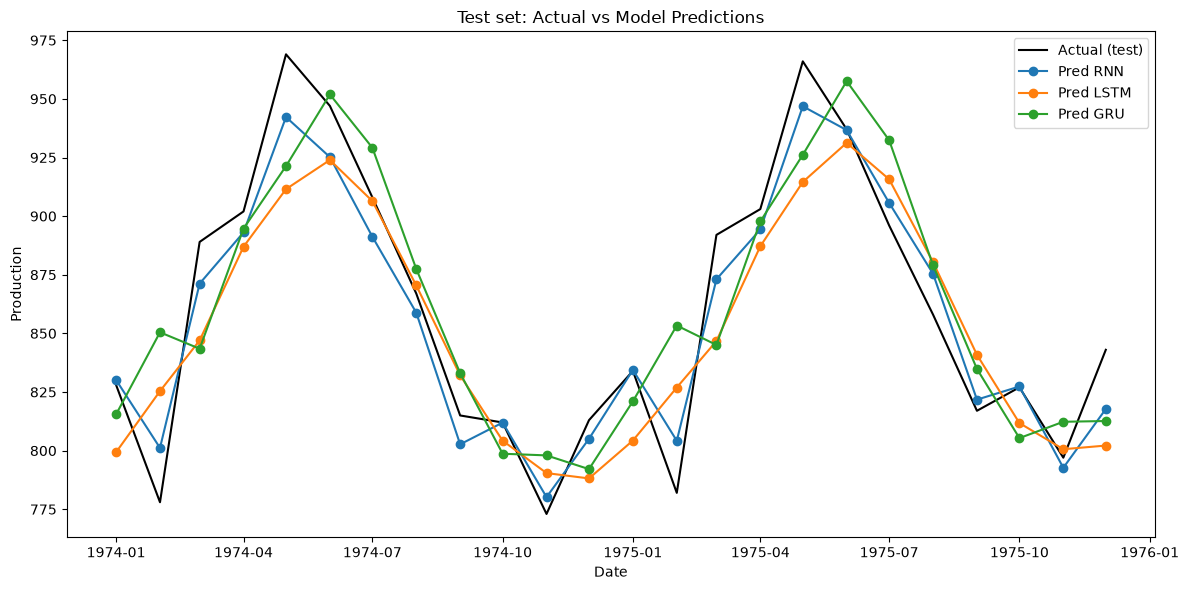

In [17]:
# ---------------------------
# Step 11: Plot test predictions vs actual
# ---------------------------
plt.figure(figsize=(12,6))
# plot actual for test period (once)
any_cell = list(results.keys())[0]
df_actual = results[any_cell]['df_test_pred']['y_true']
plt.plot(df_actual.index, df_actual.values, label='Actual (test)', color='black')
for c in ['RNN','LSTM','GRU']:
    dfp = results[c]['df_test_pred']
    plt.plot(dfp.index, dfp['y_pred'], marker='o', label=f'Pred {c}')
plt.title("Test set: Actual vs Model Predictions")
plt.xlabel("Date")
plt.ylabel("Production")
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
# Step 12: Forecast next 12 months using each model
# ---------------------------
def forecast_future(model, last_window_scaled, horizon=FORECAST_HORIZON):
    preds_scaled = []
    window = last_window_scaled.copy()
    for _ in range(horizon):
        x = window.reshape((1, window.shape[0], 1))
        p_scaled = float(model.predict(x)[0,0])
        preds_scaled.append(p_scaled)
        # slide window: drop first and append prediction
        window = np.concatenate([window[1:], [p_scaled]])
    preds = inv_scale(np.array(preds_scaled))
    return preds

last_window_scaled = y_scaled[-WINDOW_SIZE:]
future_index = pd.date_range(start=ts.index.max() + pd.offsets.MonthBegin(1), periods=FORECAST_HORIZON, freq='MS')

forecast_dfs = {}
for c in ['RNN','LSTM','GRU']:
    preds = forecast_future(results[c]['model'], last_window_scaled, FORECAST_HORIZON)
    df_f = pd.DataFrame({'ds': future_index, 'y_forecast': preds}).set_index('ds')
    forecast_dfs[c] = df_f
    print(f"\n{c} forecast head:")
    display(df_f.head())

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step

RNN forecast head:


,y_forecast
ds,
1976-01-01,844.401979
1976-02-01,809.058899
1976-03-01,879.383938
1976-04-01,892.131519
1976-05-01,941.775274


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 193ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step

LSTM forecast head:


,y_forecast
ds,
1976-01-01,821.061003
1976-02-01,831.465183
1976-03-01,862.397858
1976-04-01,883.267687
1976-05-01,901.813084


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step

GRU forecast head:


,y_forecast
ds,
1976-01-01,845.462311
1976-02-01,866.994057
1976-03-01,892.982229
1976-04-01,913.038219
1976-05-01,926.202713


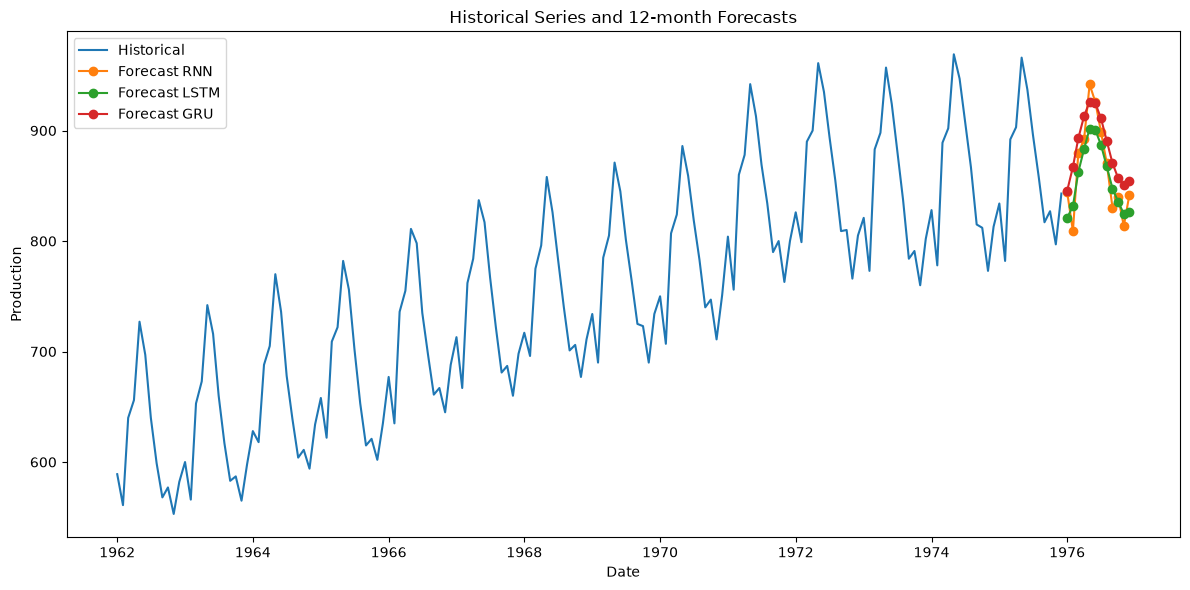

In [21]:
# Step 13: Plot historical + forecasts
# ---------------------------
plt.figure(figsize=(12,6))
plt.plot(ts.index, ts['y'], label='Historical')
for c in ['RNN','LSTM','GRU']:
    plt.plot(forecast_dfs[c].index, forecast_dfs[c]['y_forecast'], marker='o', label=f'Forecast {c}')
plt.title("Historical Series and 12-month Forecasts")
plt.xlabel("Date")
plt.ylabel("Production")
plt.legend()
plt.tight_layout()
plt.show()


MODEL PERFORMANCE COMPARISON


,RMSE,MAE,MAPE (%)
RNN,14.599,11.855,1.365
LSTM,29.883,25.181,2.925
GRU,32.381,26.618,3.128



Best-performing model based on test RMSE: RNN

RESULTS INTERPRETATION
The RNN model achieved the lowest RMSE among the three models, with an RMSE of 14.599.
Its MAE was 11.855, and its MAPE was 1.37%.
Lower RMSE, MAE, and MAPE values generally indicate better forecasting accuracy. These metrics should be considered together when comparing the models.

12-MONTH FORECAST WITH APPROXIMATE UNCERTAINTY INTERVAL


,Forecast,Lower Bound,Upper Bound
ds,,,
1976-01-01,844.40,807.86,872.73
1976-02-01,809.06,772.52,837.39
1976-03-01,879.38,842.84,907.71
1976-04-01,892.13,855.59,920.46
1976-05-01,941.78,905.23,970.10
1976-06-01,925.63,889.09,953.96
1976-07-01,898.94,862.40,927.27
1976-08-01,870.46,833.92,898.79
1976-09-01,830.26,793.72,858.59


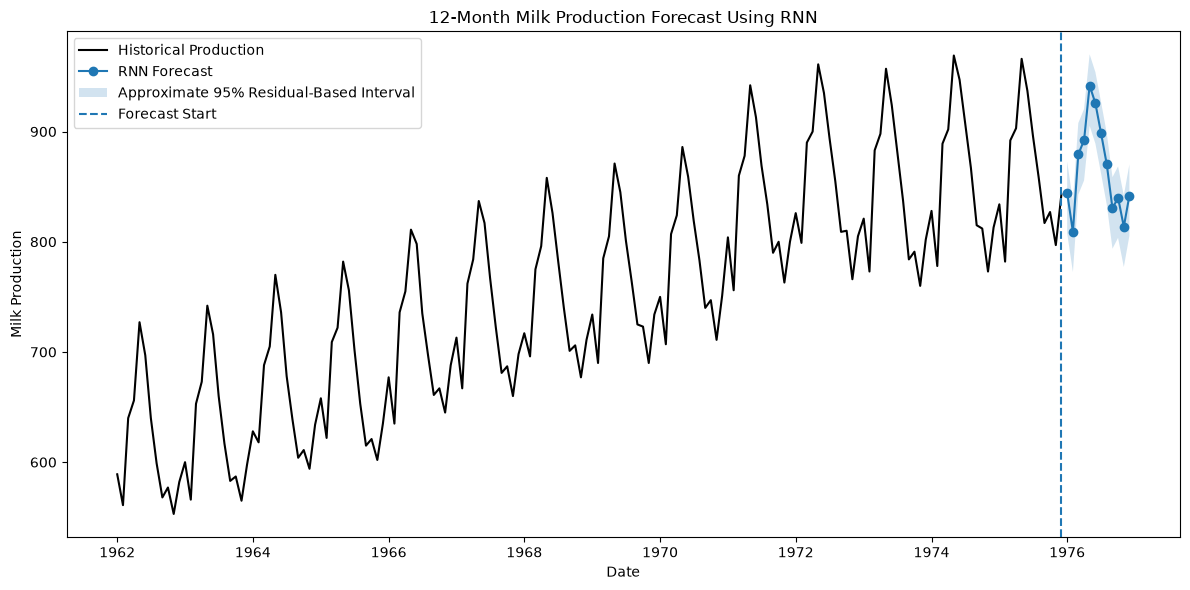


BUSINESS INSIGHTS AND RECOMMENDATIONS

1. Average predicted monthly production over the next 12 months: 865.64.
2. The lowest predicted monthly production is 809.06.
3. The highest predicted monthly production is 941.78.

4. Production Planning: Use the monthly forecasts to support production scheduling and resource planning.

5. Inventory and Storage: Use the forecasts and uncertainty intervals to help plan storage capacity and inventory requirements.

6. Distribution: Coordinate transportation and distribution schedules with expected production levels.

7. Workforce Planning: Use predicted production levels to support staffing and operational decisions.

8. Monitoring: Compare actual production with forecasts each month and update the model as new data becomes available.

Limitation: These predictions are based on historical production data. Actual production may differ because of changes in weather, herd size, feed availability, or operational conditions.

Uncertainty interval note

In [22]:
# ============================================================
# STEP 14: RESULTS INTERPRETATION AND BUSINESS RECOMMENDATIONS
# ============================================================

# 1. Compare the three models using their actual test results

metrics = pd.DataFrame({
    model_name: results[model_name]["metrics"]
    for model_name in ["RNN", "LSTM", "GRU"]
}).T

metrics.columns = ["RMSE", "MAE", "MAPE (%)"]

print("MODEL PERFORMANCE COMPARISON")
display(metrics.round(3))

# Select the model with the lowest test RMSE
best_model_name = metrics["RMSE"].idxmin()

print("\nBest-performing model based on test RMSE:", best_model_name)

print("\nRESULTS INTERPRETATION")

print(
    f"The {best_model_name} model achieved the lowest RMSE "
    f"among the three models, with an RMSE of "
    f"{metrics.loc[best_model_name, 'RMSE']:.3f}."
)

print(
    f"Its MAE was {metrics.loc[best_model_name, 'MAE']:.3f}, "
    f"and its MAPE was "
    f"{metrics.loc[best_model_name, 'MAPE (%)']:.2f}%."
)

print(
    "Lower RMSE, MAE, and MAPE values generally indicate "
    "better forecasting accuracy. These metrics should be "
    "considered together when comparing the models."
)


# ============================================================
# STEP 15: APPROXIMATE FORECAST UNCERTAINTY INTERVAL
# ============================================================

# Obtain validation predictions for the selected model
best_model = results[best_model_name]["model"]

val_predictions_scaled = best_model.predict(
    X_val_r, verbose=0
).flatten()

val_actual = inv_scale(Y_val)
val_predictions = inv_scale(val_predictions_scaled)

# Calculate validation residuals
validation_residuals = val_actual - val_predictions

# Estimate an approximate 95% residual-based interval
lower_residual = np.percentile(validation_residuals, 2.5)
upper_residual = np.percentile(validation_residuals, 97.5)

# Get the selected model's 12-month forecast
selected_forecast = forecast_dfs[best_model_name]["y_forecast"]

# Calculate lower and upper bounds
lower_bound = np.maximum(
    selected_forecast.values + lower_residual, 0
)

upper_bound = (
    selected_forecast.values + upper_residual
)

# Create a forecast table with the uncertainty interval
forecast_with_interval = pd.DataFrame({
    "Forecast": selected_forecast.values,
    "Lower Bound": lower_bound,
    "Upper Bound": upper_bound
}, index=selected_forecast.index)

print("\n12-MONTH FORECAST WITH APPROXIMATE UNCERTAINTY INTERVAL")
display(forecast_with_interval.round(2))


# ============================================================
# STEP 16: VISUALIZE FORECAST AND UNCERTAINTY INTERVAL
# ============================================================

plt.figure(figsize=(12, 6))

# Historical production
plt.plot(
    ts.index,
    ts["y"],
    label="Historical Production",
    color="black"
)

# Forecast
plt.plot(
    selected_forecast.index,
    selected_forecast.values,
    marker="o",
    label=f"{best_model_name} Forecast"
)

# Uncertainty interval
plt.fill_between(
    selected_forecast.index,
    lower_bound,
    upper_bound,
    alpha=0.2,
    label="Approximate 95% Residual-Based Interval"
)

plt.axvline(
    ts.index.max(),
    linestyle="--",
    label="Forecast Start"
)

plt.title(
    f"12-Month Milk Production Forecast Using {best_model_name}"
)

plt.xlabel("Date")
plt.ylabel("Milk Production")
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# STEP 17: BUSINESS INSIGHTS AND RECOMMENDATIONS
# ============================================================

forecast_mean = selected_forecast.mean()
forecast_min = selected_forecast.min()
forecast_max = selected_forecast.max()

print("\nBUSINESS INSIGHTS AND RECOMMENDATIONS")

print(
    f"\n1. Average predicted monthly production over the next "
    f"12 months: {forecast_mean:.2f}."
)

print(
    f"2. The lowest predicted monthly production is "
    f"{forecast_min:.2f}."
)

print(
    f"3. The highest predicted monthly production is "
    f"{forecast_max:.2f}."
)

print(
    "\n4. Production Planning: Use the monthly forecasts "
    "to support production scheduling and resource planning."
)

print(
    "\n5. Inventory and Storage: Use the forecasts and "
    "uncertainty intervals to help plan storage capacity "
    "and inventory requirements."
)

print(
    "\n6. Distribution: Coordinate transportation and "
    "distribution schedules with expected production levels."
)

print(
    "\n7. Workforce Planning: Use predicted production "
    "levels to support staffing and operational decisions."
)

print(
    "\n8. Monitoring: Compare actual production with forecasts "
    "each month and update the model as new data becomes available."
)

print(
    "\nLimitation: These predictions are based on historical "
    "production data. Actual production may differ because of "
    "changes in weather, herd size, feed availability, or "
    "operational conditions."
)

print(
    "\nUncertainty interval note: The shaded band is an "
    "approximate residual-based prediction interval. It is "
    "not a guaranteed range and may not fully represent "
    "uncertainty over the 12-month forecasting horizon."
)